In [1]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.notebook import tqdm
import seaborn as sns

from scipy.optimize import minimize
from scipy.spatial import ConvexHull

### Подготовка данных

In [2]:
# Загружаем экспериментальный спектр фольги
foil_spectrum_exp = np.loadtxt('../source_data/PtL3_foil.txt')
# Выравнивание эксперимента по краю поглощения (максимум производной)
d_exp = (foil_spectrum_exp[1:, 1] - foil_spectrum_exp[:-1, 1]) / (foil_spectrum_exp[1:, 0] - foil_spectrum_exp[:-1, 0])
# Находим индекс максимального наклона и соответствующую энергию края
E_edge_exp = foil_spectrum_exp[np.argmax(d_exp), 0]

# Переводим экспериментальную сетку в относительную шкалу (E - E_edge)
EXPERIMENT = foil_spectrum_exp.copy()
EXPERIMENT[:, 0] = foil_spectrum_exp[:, 0] - E_edge_exp

In [3]:
# Загрузка неразмазанных теоретических спектров
# Будем загружать сразу с плотной сеткой по причинам озвученным в документе 03.0.Spectral_smearing_issues_SupplementaryMat

# SPECTRA_ROOT = Path('../source_data/Unique_Spectra/')               # Теория с "стандартной" сеткой.

SPECTRA_ROOT = Path('../source_data/Unique_Spectra_dense/')           # Теория с густой сеткой энергии.
SPECTRA_PATH_LIST_not_conv = list(SPECTRA_ROOT.glob('*/Pt.txt'))
SORTED_SPECTRA_PATH_LIST_not_conv = sorted(SPECTRA_PATH_LIST_not_conv, key=lambda x: int(x.parent.name))

In [4]:
# Загружаем набор данных с уникальными подструктурами входящими в состав наших 800 НЧ.
# Среди подструктур только 1 является истинно "объемной" (теор.фольга)
# Остальные же являются в разной степени поверхностными, однако среди них можно выделить "около объемные"
# т.е. такие подструктуры которые ближе к объемным НК.
unique_substructures_df = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')

# Загружаем данные собранные из .bav файлов расчетов FDMNESS
# файл содержит данные о значениях EF (E_Fermi) и natomsym
# natomsym является множителем для теоретического спектра в соответствии с найденными тождественными подструктурами самим FDMNNESS'ом.
# т.е. дли приведения к единому масштабу (mu) спектров нужно их поделить на соответствующие множители.
EF_SHIFTS_BAV = pd.read_csv('../source_data/EF_natomsym_id.txt',delimiter=' ')

EF_SHIFTS_BAV['id_structure'] = EF_SHIFTS_BAV['id_structure'].astype(int)
EF_SHIFTS_BAV = EF_SHIFTS_BAV.set_index('id_structure')

# Объединим данные в единый ДатаФрейм для удобства.
MERGED_DF = pd.merge(left=unique_substructures_df,right=EF_SHIFTS_BAV, how='left', left_index=True, right_index=True)
# Вводим данные о сдвиге EF для данных НК относительно теоретической "фольги" (самой крупной подструктуры с полностью заполненными 7 сфрерами)
MERGED_DF['EF'] = MERGED_DF['EF']-MERGED_DF['EF'].loc[2045]

# Вводим столбец с данными о сдвиге центра масс относительно поглощающего атома, находящегося для каждой НК в 0 координат.
# Этот параметр является в некотором роде показателем "степени поверхностности" конкретной подструктуры (НК).
MERGED_DF['d_cm'] = MERGED_DF['Structure'].apply(lambda x: (((x.get_center_of_mass()**2).sum())**0.5).round(4))

# Вводим размер в Ангстремах для каждого НК, размер - диаметр описанной вокруг НК окружности (максимальное расстояние между всеми парами атомов).
MERGED_DF['size'] =  MERGED_DF['Structure'].apply(lambda x: x.get_all_distances().max().round(4))

# Нормированный сдвиг центра масс (нормируем на размер НК)
MERGED_DF['d_cm_normed'] =  MERGED_DF['d_cm']/MERGED_DF['size']

# Вводим отдельные значения для Координационных чисел (КЧ) и их нормированных вариантов (отн. макс. теор. значения).
MERGED_DF['CN1']=np.array(MERGED_DF['CN'].values.tolist())[:,0]
MERGED_DF['CN2']=np.array(MERGED_DF['CN'].values.tolist())[:,1]
MERGED_DF['CN3']=np.array(MERGED_DF['CN'].values.tolist())[:,2]
MERGED_DF['CN4']=np.array(MERGED_DF['CN'].values.tolist())[:,3]
MERGED_DF['CN5']=np.array(MERGED_DF['CN'].values.tolist())[:,4]
MERGED_DF['CN6']=np.array(MERGED_DF['CN'].values.tolist())[:,5]
MERGED_DF['CN7']=np.array(MERGED_DF['CN'].values.tolist())[:,6]

MERGED_DF['CN1_n']=MERGED_DF['CN1']/12
MERGED_DF['CN2_n']=MERGED_DF['CN2']/6
MERGED_DF['CN3_n']=MERGED_DF['CN3']/24
MERGED_DF['CN4_n']=MERGED_DF['CN4']/12
MERGED_DF['CN5_n']=MERGED_DF['CN5']/24
MERGED_DF['CN6_n']=MERGED_DF['CN6']/8
MERGED_DF['CN7_n']=MERGED_DF['CN7']/48

# Введем средние координационные числа для ближнего (1-3) и дальнего (5-7) порядка в НК
MERGED_DF['CN_near'] = (MERGED_DF['CN1_n']+MERGED_DF['CN2_n']+MERGED_DF['CN3_n'])/3
MERGED_DF['CN_far']  = (MERGED_DF['CN6_n']+MERGED_DF['CN7_n']+MERGED_DF['CN5_n'])/3

In [5]:
# Определим параметры сетки энергии для спектров XANES используемые в блокноте
E_MIN = -10
E_MAX = 100
E_STEP = 0.05
E_ARRAY = np.arange(E_MIN,E_MAX+1e-5,E_STEP)

In [6]:
%%time
# Кэшируем спектры 
shifted_spectra_cache = {}
for ind in MERGED_DF.index.to_list():
    spectra_ = np.loadtxt(SORTED_SPECTRA_PATH_LIST_not_conv[ind], skiprows=2)
    EF = MERGED_DF.EF.loc[ind]
    n_atom_sym = MERGED_DF.natomsym.loc[ind]
    y_new = spectra_[:,1]/n_atom_sym               # компенсируем учет неэквивалентных позиций из расчета FDMNESS (собраны из bav файла)
    x_shifted = spectra_[:,0] - EF                 # сдвигаем все спектры на значение EF (собраны из bav файла) (сдвиг относительно т.фольги).
    y_new = np.interp(E_ARRAY,x_shifted,y_new)     # Интерполируем к заданной шкале энергий.
    spectra_ = np.column_stack((E_ARRAY,y_new))
    shifted_spectra_cache[ind]=spectra_

CPU times: total: 6.42 s
Wall time: 6.44 s


In [7]:
%%time
# Кэшируем усредненные спектры для некоторых разбиений НК по размерам.

# bins = (0,20,30,40,50,60,80,100,120,134,136)
bins = tuple([0]+sorted(unique_substructures_df.Num_atoms.unique().tolist()))


binned_spectra_cache = {}

for start, end in zip(bins[:-1], bins[1:]):
    bin_name = (start, end)
    tdf = unique_substructures_df.query(f'Num_atoms>{start} and Num_atoms<={end}').copy()
    spectra_indecies = tdf.index.values
    
    spectra_sublist = [shifted_spectra_cache[ind] for ind in spectra_indecies]
    
    x_axis = spectra_sublist[0][:, 0]
    all_y = np.array([spec[:, 1] for spec in spectra_sublist])
    mean_y = np.mean(all_y, axis=0)

    binned_spectra_cache[bin_name] = np.column_stack((x_axis, mean_y))


CPU times: total: 297 ms
Wall time: 300 ms


In [8]:
# Вынесем в отдельную переменную спектр теор. фольги
foil_spectrum_without_smearing = shifted_spectra_cache[2045].copy()

### Определим необходимые функции

In [9]:
# Функция размазки спектра
def get_spectra_conv(param:dict,spectra,E_step:float=0.1):
    '''
    Функция для размазки теоретических спектров, возвращает кортеж (Gamma, new_spectrum)
    Принимает 3 параметра: 
        param - список параметров размазки; 
        spectra - неразмазанный теор. спектр; 
        E_step - шаг интерполяции для размазки.
        
    param - словарь именованных параметров:
        p0      - значение E_Fermi;
        p1      - Положение перегиба арктангенса;
        p2      - Gamma_max (добавочное уширение);
        p3      - Gamma_hole (базовое уширение) (для Pt значение около 5.33);
        p4      - Коэффициент затухания/крутизна арктангенса;
        dE0     - Сдвиг спектра как единого целого вдоль оси энергий;
        stretch - Равномерное растяжение/сжатие спектра вдоль оси энергий (как множитель)
                  (компенсация потенциального несоответствия параметров решетки теории и эксперимента).
                  
    параметры "p" являются обязательными, dE0 и stretch в случае отсутствия в словаре берутся за 0 и 1 соответственно.
    '''
    
    E_array = np.arange(spectra[:,0].min(),spectra[:,0].max(),E_step)
    
    dE0 = param.get("dE0", 0.0)
    stretch = param.get("stretch", 1.0)

    # растягиваем/сжимаем сетку энергий вокруг нуля 
    scaled_theory_energy = (spectra[:, 0] - param["p0"]) * stretch
    scaled_theory_energy = scaled_theory_energy + param["p0"] + dE0
    #((spectra[:, 0]-param["p0"]+dE0) * stretch)
    
    # Интерполируем интенсивность на новую сетку
    spectraTh = np.interp(E_array, scaled_theory_energy, spectra[:, 1])
    
    paramConv   = [param["p0"]+dE0,param["p1"]+dE0,param["p2"],param["p3"],param["p4"]]
    
    #############################################
    delta_e = E_array - paramConv[0]
    Gamma = np.full_like(E_array, paramConv[3])
    #############################################
    
    spectraTh = spectraTh[E_array>=paramConv[0]]
    eParam = (E_array[delta_e>0]-paramConv[0])/(paramConv[1]-paramConv[0])

    Gamma[delta_e>0] = (paramConv[3] + paramConv[2]*(0.5+np.arctan(paramConv[4]*(eParam-1/(eParam*eParam+(1e-20))))/np.pi))

    convSpectrum = np.zeros(len(E_array))

    for indx in (np.arange(len(E_array))):
        conv = Gamma[indx]/((E_array[E_array>=paramConv[0]]-E_array[indx])**2+Gamma[indx]**2/4)
        convSpectrum[indx] = (conv*spectraTh).sum()
    
    return Gamma, convSpectrum

In [10]:
# Функция для оценки невязки между теоретическим не размазанным спектром, и экспериментом, выравненным по краю поглощения
def get_error(x, param_names, raw_theory_spectra, exp_spectra, emin, emax, norm_mod:str = 'Area', EF_fix:float=None):
    """
    Вычисляет среднеквадратичную разность между размазанной теорией 
    и экспериментом, выравненным по краю поглощения, с масштабной нормировкой.
    norm_mode ['Area','Max']:
        Area - оптимальное масштабирование по L2 (проекция), минимизирует MSE при свободном множителе. 
               Менее чувствительна к абсолютной интенсивности (игнорирует систематический сдвиг), но более чувствительна к "форме".
        Max - выравнивает по максимальному значению интенсивности поглощения, сильнее штрафует за несоответствие интенсивностей.
              Чувствителен к выборку окна и выбросам.
    """

    assert norm_mod in ['Area','Max'], 'допустимые значения для norm_mod ["Area","Max"]'
    
    current_params = dict(zip(param_names, x))
    if EF_fix:
        current_params['p0']=EF_fix
        
    _, conv_y = get_spectra_conv(current_params, raw_theory_spectra, E_STEP)

    E_array = np.arange(raw_theory_spectra[:, 0].min(), raw_theory_spectra[:, 0].max(), E_STEP)
    
    loss_mask = (E_array >= emin) & (E_array <= emax)
    E_fit = E_array[loss_mask]
    conv_y_fit = conv_y[loss_mask]
    
    exp_y_interp = np.interp(E_fit, exp_spectra[:, 0], exp_spectra[:, 1])

    if norm_mod=='Area':
        Coef_norm = np.dot(exp_y_interp, conv_y_fit) / (np.dot(conv_y_fit, conv_y_fit)+1e-20)
        Coef_norm = float(Coef_norm)    
        residuals = Coef_norm * conv_y_fit - exp_y_interp
    else:
        residuals = conv_y_fit/conv_y_fit.max() - exp_y_interp/exp_y_interp.max()
    
    eps = np.dot(residuals, residuals)

    return eps / len(E_fit)

In [11]:
def get_wl_area(ind, params, emin, emax, E_step):
    '''
    Функция для вычисления интегральной интенсивности размазанного спектра в диапазоне от emin до emax
    ind - индекс спектра,
    params - параметры для функции размазки
    emin, emax - границы маски для интегрирования
    E_step - шаг интерполяции спектра перед интегрированием.
    '''
    spectra_ = shifted_spectra_cache[ind]
    E_array = np.arange(spectra_[:,0].min(),spectra_[:,0].max(),E_step)
    mask_energy = (E_array>=emin)&(E_array<=emax)
    _, spectra_conv = get_spectra_conv(param=params,spectra=spectra_, E_step=E_step)
    return np.trapezoid(spectra_conv[mask_energy],E_array[mask_energy])

In [12]:
# Функция для получения расстояния от погл. атома до ближайшей поверхности НЧ, корректная мера "поверхностности".
def get_min_distance_to_hull(positions:np.ndarray):
    """
    Находит минимальное расстояние от поглощающего атома внутри ConvexHull до его поверхности.
    """
    p = np.array([0,0,0])

    hull = ConvexHull(positions)
    # hull.equations содержит коэффициенты [A, B, C, D] для каждой грани
    # Уравнение плоскости: A*x + B*y + C*z + D = 0
    # Нормали [A, B, C] в scipy уже нормализованы (их длина равна 1) и направлены НАРУЖУ
    
    A_B_C = hull.equations[:, :-1]  # Матрица нормалей (N, 3)
    D = hull.equations[:, -1]       # Вектор сдвигов (N,)
    
    # Расстояние от точки до плоскостей (с учетом знака). 
    # Так как нормали смотрят наружу, для внутренней точки значения будут отрицательными.
    # Берем абсолютное значение.
    distances = np.abs(np.dot(A_B_C, p) + D)
    
    # Возвращаем минимальное расстояние
    return np.min(distances).round(4)

In [13]:
MERGED_DF['surface_proximity'] =  MERGED_DF['Structure'].apply(lambda x: get_min_distance_to_hull(x.positions))

MERGED_DF['surface_proximity_normed'] = MERGED_DF['surface_proximity']/MERGED_DF['size']

## Проведем оптимизацию параметров размазки для наилучшего описания экспериментальной фольги

In [14]:
# Стартовые параметры для оптимизации
paramConvInit = [0.7, 39.5, 14.7, 5.33, 0.27,0.51,1.03]
param_names = ['p0', 'p1', 'p2', 'p3', 'p4','dE0','stretch']
initial_guess = np.array(paramConvInit)
norm_mode = 'Max' # 'Area',
# Физические ограничения для параметров (min, max)
bounds = [
            (-5,5),         # p0 (E_Fermi сдвиг)
            (5.0, 100.0),   # p1 (Полоэение перегиба)
            (1.0, 70.0),    # p2 (Gamma_max добавочное уширение)
            (5.30, 5.35),   # p3 (Gamma_hole)
            (0.01, 5.0),    # p4 (Коэффициент затухания/крутизны)
            (-10.,10.),     # dE0 
            (0.95,1.05)     # stretch
         ]

# Диапазон энергий (относительно E-E0), в котором оптимизатор будет сравнивать графики
E_min_fit = -10.0
E_max_fit = 60.0

In [15]:
%%time

res = minimize(fun=get_error,
               x0=initial_guess,
               args=(param_names, foil_spectrum_without_smearing, EXPERIMENT, E_min_fit, E_max_fit, norm_mode),
               method='L-BFGS-B',
               bounds=bounds,
               options={'disp': True, 'maxiter': 100, 'gtol': 1e-20}
              )

print("\n--- Результаты оптимизации ---")
optimized_params = dict(zip(param_names, res.x))
for name, val in optimized_params.items():
    print(f"{name}: {val:.6f}")

print('Error: ', np.round(get_error(res.x,param_names,foil_spectrum_without_smearing, EXPERIMENT, E_min_fit, E_max_fit, norm_mode),6))


--- Результаты оптимизации ---
p0: 0.729470
p1: 39.445336
p2: 14.983698
p3: 5.350000
p4: 0.248619
dE0: 0.520530
stretch: 1.038219
Error:  0.000119
CPU times: total: 24.7 s
Wall time: 24.7 s


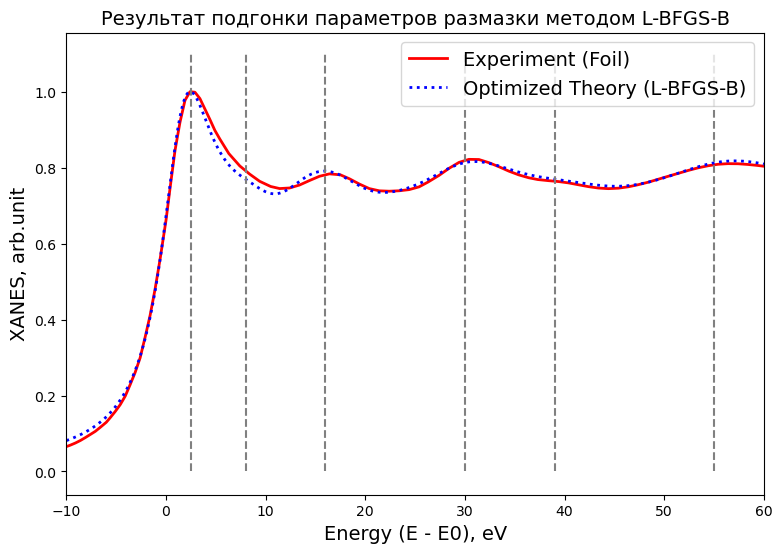

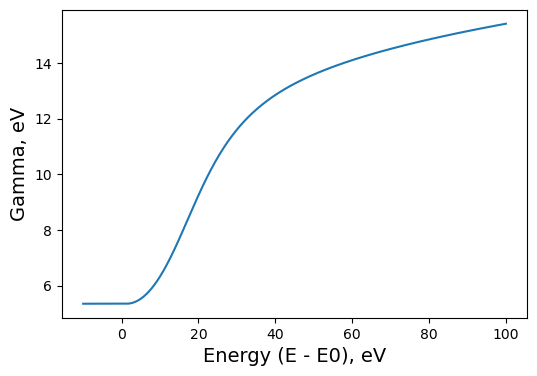

In [16]:
final_Gamma, final_conv_spectrum = get_spectra_conv(optimized_params, foil_spectrum_without_smearing,E_STEP)

plt.figure(figsize=(9, 6))
plt.plot(EXPERIMENT[:, 0], EXPERIMENT[:, 1] / EXPERIMENT[:, 1].max(), 'r-', label='Experiment (Foil)', linewidth=2)
plt.plot(E_ARRAY, final_conv_spectrum / final_conv_spectrum.max(), 'b:', label='Optimized Theory (L-BFGS-B)', linewidth=2)
plt.vlines(x=[2.5,8,16,30,39,55],ymin=0,ymax=1.1,colors='gray',ls='--')

plt.xlim(E_min_fit, E_max_fit)
plt.title('Результат подгонки параметров размазки методом L-BFGS-B',fontsize=14)
plt.xlabel('Energy (E - E0), eV', fontsize=14)
plt.ylabel('XANES, arb.unit', fontsize=14)
plt.legend(fontsize=14)

plt.savefig('../images/XANES_foil_conv_spectrum_quality.png', dpi=600)

plt.show()


plt.figure(figsize=(6, 4))
plt.plot(E_ARRAY,final_Gamma)
plt.xlabel('Energy (E - E0), eV', fontsize=14)
plt.ylabel('Gamma, eV', fontsize=14)

plt.savefig('../images/XANES_foil_conv_gamma.png', dpi=600)

plt.show()

## Построим графики неразмазанных спектров с полученными значениями dE0 и EF

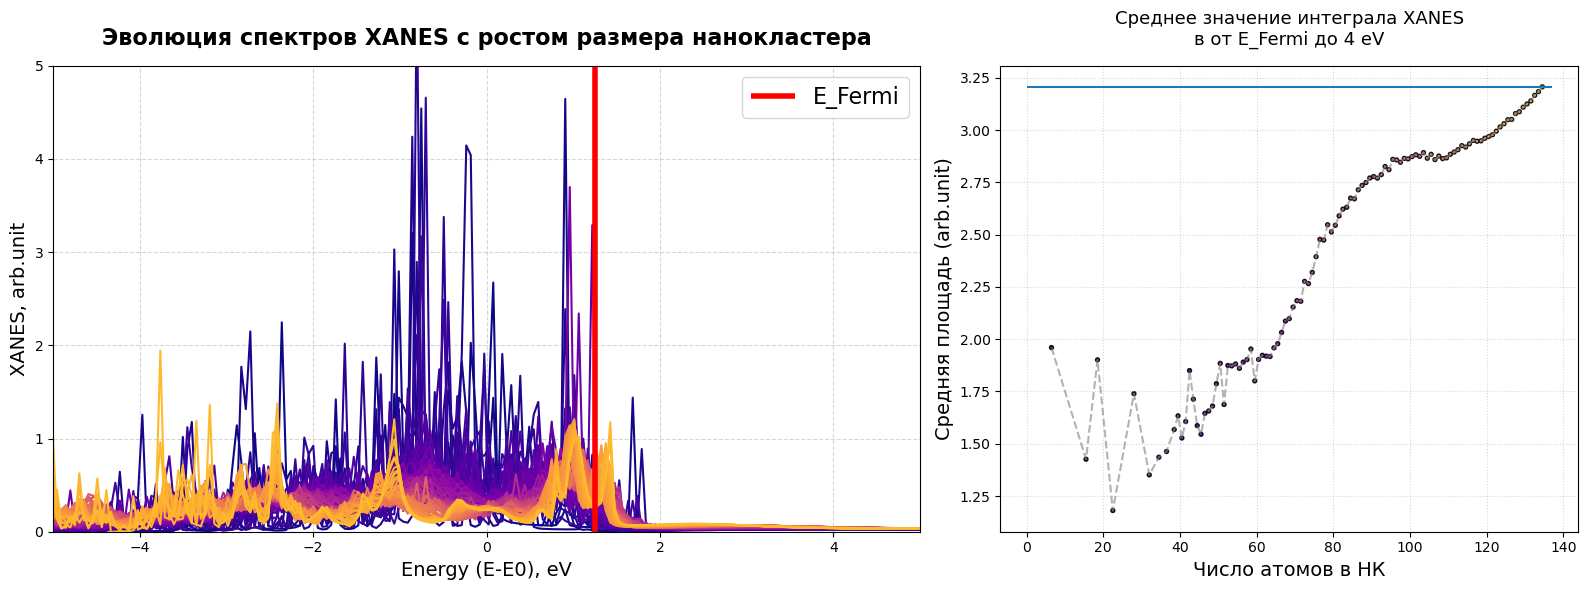

In [17]:
EF = 0.73
dE0 = 0.52
stretch = 1.038

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.5, 1]})

colors = plt.cm.plasma(np.linspace(0, 0.85, len(bins)-1))

mean_spectra = []
bin_centers = []

for i, (start, end) in enumerate(zip(bins[:-1], bins[1:])):
    bin_name = (start, end)
    spectra = binned_spectra_cache[bin_name]
    mean_spectra.append(spectra[:,1])
    bin_centers.append((start + end) / 2)
    spectra_x = (spectra[:, 0] - EF) * stretch
    spectra_x = spectra_x + EF + dE0
    ax1.plot(spectra_x, spectra[:,1], color=colors[i], linewidth=1.5)
             #label=f'Num_atoms: [{start}, {end})')




ax1.vlines(EF+dE0,0,10, color='red', lw=4,label='E_Fermi')
ax1.set_title('Эволюция спектров XANES с ростом размера нанокластера', 
              fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel('Energy (E-E0), eV', fontsize=14)
ax1.set_ylabel('XANES, arb.unit', fontsize=14)
ax1.legend(fontsize=16)
ax1.set_xlim(-5, 5)
ax1.set_ylim(0, 5)

ax1.grid(True, linestyle='--', alpha=0.5)



energy_range_mask = (x_axis >= EF+dE0) & (x_axis <= 4)
area_values = [np.trapezoid(spec[energy_range_mask]) for spec in mean_spectra]

ax2.scatter(bin_centers, area_values, c=colors[:len(area_values)], s=8, alpha=0.9, edgecolors='k')
ax2.hlines(area_values[-1],0,137)
ax2.plot(bin_centers, area_values, color='gray', linestyle='--', alpha=0.6)

ax2.set_title(f'Среднее значение интеграла XANES\nв от E_Fermi до 4 eV', fontsize=13, pad=15)
ax2.set_xlabel('Число атомов в НК', fontsize=14)
ax2.set_ylabel('Средняя площадь (arb.unit)', fontsize=14)
ax2.grid(True, linestyle=':', alpha=0.5)


plt.tight_layout()
plt.savefig('../images/XANES_noc_conv_dense_with_EF.png', dpi=600)
plt.show()

In [18]:
# Из данных для редкой сетки расчета спектров мы полагали, что EF вероятно будет распологаться в районе 0 для выравненных спектров.
# Однако настроенные по фольге параметры показывают, что EF находится в первом локальном минимуме для "крупных" НК
# на значении энергии ~1.2 eV с учетом сдвига спектра (EF=0.7 dE0=0.5).
# При этом интеграл от спектра XANES в диапазоне от EF до 4 eV показывает что с уменьшением размера НК
# (приближении к поверхности) в среднем интенсивность белой линии уменьшается.

## Посмотрим зависимости интегральных интенсивностей белой линии размазанных спектров от размера/степени поверхностности НК

In [19]:
%%time
# Посчитаем соответствующие интенсивности для спектров
area_dict = {}
for ind in tqdm(MERGED_DF.index.tolist()):
    area_dict[ind] = get_wl_area(ind, optimized_params, -10, 10, 0.05)

  0%|          | 0/2151 [00:00<?, ?it/s]

CPU times: total: 1min 51s
Wall time: 1min 51s


In [20]:
# Создадим временный ДатаФрейм с интегральными интенсивностями и объеденим его с нашим MERGED_DF
area_df = pd.DataFrame(list(area_dict.items()), columns=['index', 'areas'])
area_df = area_df.set_index('index')
area_df = area_df.round(3)

MERGED_DF = MERGED_DF.merge(area_df, how='left', left_index=True, right_index=True)

### Построим график зависимости интенсивностей в координатах CN_near, CN_far

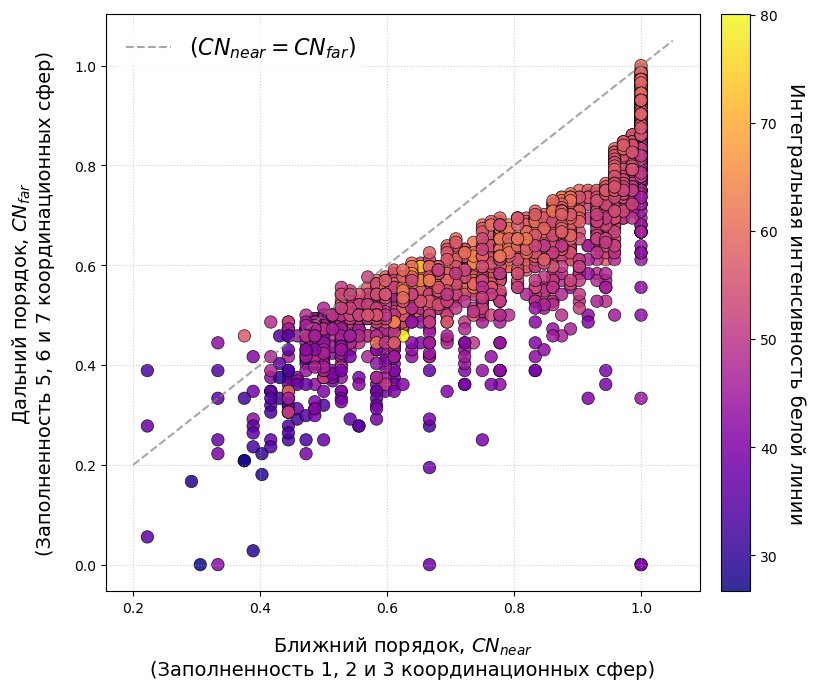

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 7))

ax.plot([0.2,1.05], [0.2,1.05], '--', color='gray', alpha=0.7, linewidth=1.5, label='($CN_{near} = CN_{far}$)')

# Отображаем наши НК в виде точек, где цвет зависит от площади белой линии (areas)
scatter = ax.scatter(MERGED_DF['CN_near'], 
                     MERGED_DF['CN_far'],
                     c=MERGED_DF['areas'],  
                     cmap='plasma', 
                     s=80,               # Размер точек
                     edgecolors='black', # Обводка для лучшей читаемости накладывающихся точек 
                     linewidths=0.5, 
                     alpha=0.85
                    )

cbar = fig.colorbar(scatter, ax=ax, pad=0.03)
cbar.set_label('Интегральная интенсивность белой линии', rotation=270, labelpad=20, fontsize=14)

ax.set_xlabel('Ближний порядок, $CN_{near}$ \n(Заполненность 1, 2 и 3 координационных сфер)', labelpad=14, fontsize=14)
ax.set_ylabel('Дальний порядок, $CN_{far}$ \n(Заполненность 5, 6 и 7 координационных сфер)', labelpad=14, fontsize=14)

ax.grid(True, linestyle=':', alpha=0.6, zorder=1)
ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none', fontsize=16)

plt.tight_layout()

plt.savefig('../images/XANES_wl_intensities_CNnear_CNfar.png', dpi=600)

plt.show()

In [22]:
# Приведенный график хоть и информативен, тем не менее, труден для интерпретации
# Точки близкие к главной диагонали при значениях менее 0.6 ориентировачно характеризуют поверхностные НК для средних и крупных НЧ;
# Точки лежащие заметно ниже главной диагонали при этих в этом же диапазоне - поверхностные НК для малых НЧ;
# У нас есть всего 1 точка с координатами 1,1 которая является "теоретической фольгой".
# Точки лежащие внутри коридора 0.4-0.9 по CN_far и >0.6 по CN_near можно считать "псевдо" объемными.
# Видно, что для псевдо объемных точек есть значительная часть с интенсивностью белой линии выше теор. фольги.
# Однако и для более "поверхностных точек наблюдаются "выбросы" с большой интенсивностью белой линии.

### Построим график зависимости интенсивности белой линии как функцию расстояния от погл. атома, до центра масс НК.

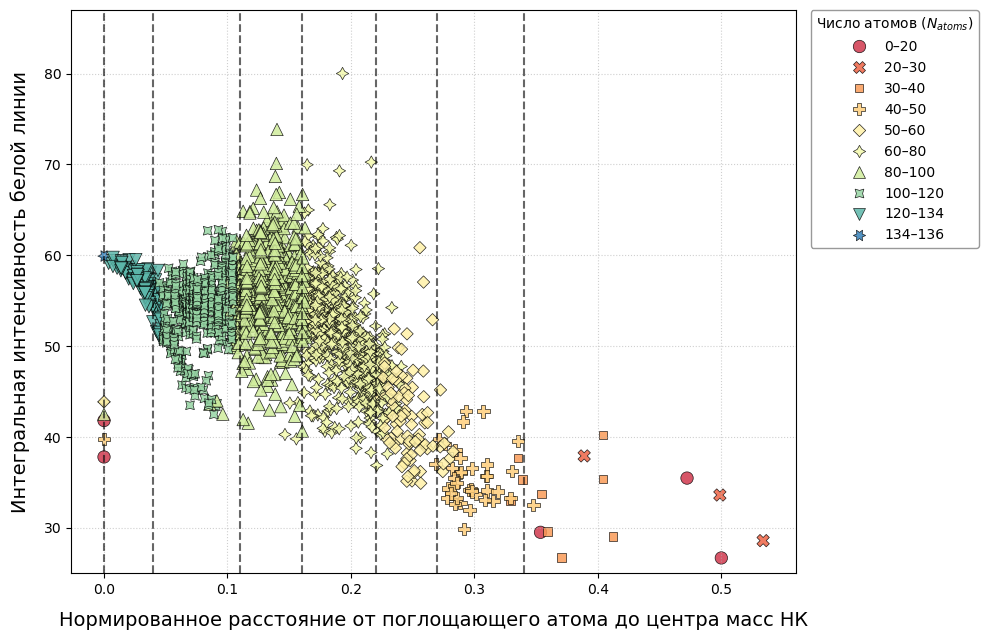

In [23]:
data = MERGED_DF.copy()
atom_col = 'Num_atoms'
d_cm_col = 'd_cm_normed'
area_col = 'areas'
custom_bins = (0, 20, 30, 40, 50, 60, 80, 100, 120, 134, 136)

# Создаем текстовые метки вида "0-20", "20-30" и т.д.
labels = [f"{custom_bins[i]}–{custom_bins[i+1]}" for i in range(len(custom_bins) - 1)]

# Разбиваем Num_atoms на интервалы (включая правый край)
data['atom_bin'] = pd.cut(data[atom_col], 
                          bins=custom_bins, 
                          labels=labels, 
                          include_lowest=True
                         )
                        
# Удаляем строки, которые не попали ни в один из диапазонов (если такие есть)
data = data.dropna(subset=['atom_bin'])

# Настройка стиля и палитры
fig, ax = plt.subplots(figsize=(10, 6.5))
palette = sns.color_palette("Spectral", n_colors=len(labels)) # viridis, plasma

# Построение диаграммы рассеяния
scatter_plot = sns.scatterplot(data=data, 
                               x=d_cm_col, 
                               y=area_col, 
                               hue='atom_bin', 
                               palette=palette, 
                               style='atom_bin',     # Разные маркеры для дополнительной читаемости
                               s=80,                 # Размер точек
                               edgecolor='black', 
                               linewidth=0.5, 
                               alpha=0.85, 
                               ax=ax
                              )

ax.vlines([0, 0.04,0.11, 0.16,0.22,0.27,0.34],25,90,color='black',ls='--', alpha=0.6)
ax.set_ylim(25,87)

ax.set_xlabel('Нормированное расстояние от поглощающего атома до центра масс НК', fontsize=14, labelpad=10)
ax.set_ylabel('Интегральная интенсивность белой линии', fontsize=14, labelpad=10)

ax.grid(True, linestyle=':', alpha=0.6)

ax.legend(title='Число атомов ($N_{atoms}$)', 
          bbox_to_anchor=(1.02, 1), 
          loc='upper left', 
          borderaxespad=0, 
          frameon=True, 
          facecolor='white', 
          edgecolor='gray' 
         )

plt.tight_layout()

plt.savefig('../images/XANES_wl_intensities_D_CM.png',dpi=600)

plt.show()

In [24]:
# Данный график дает несколько более "наглядную" картину зависимости интенсивности белой линии (БЛ) от "поверхностности" НК.
# Видно, что для истинно "объемных" НК фольга дает наибольшую интенсивность БЛ.
# В целом тенденция такая, что с увеличением расстояния от поглощающего атома до центра масс интенсивность БЛ уменьшается.
# При этом существует "горб" для "псевдо" объемных НК, показывающий интенсивности БЛ выше чем у теор. фольги.

### Построим график зависимости интенсивности БЛ как функцию от расстояния от погл. атома до ближайшей поверхности НК

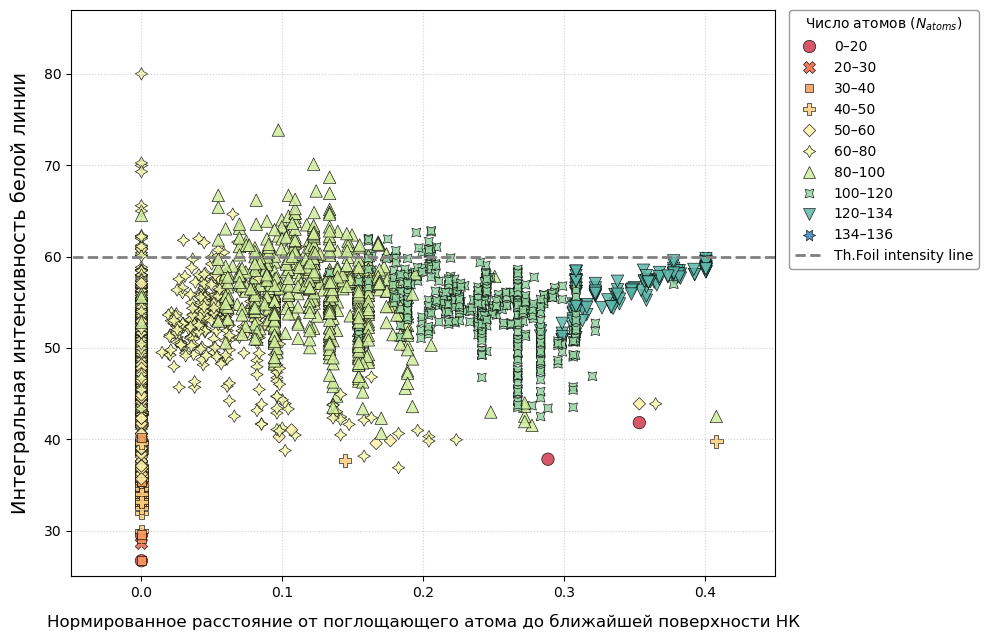

In [25]:
data = MERGED_DF.copy()
atom_col = 'Num_atoms'
d_cm_col = 'surface_proximity_normed' #surface_proximity
area_col = 'areas'
custom_bins = (0, 20, 30, 40, 50, 60, 80, 100, 120, 134, 136)

labels = [f"{custom_bins[i]}–{custom_bins[i+1]}" for i in range(len(custom_bins) - 1)]

data['atom_bin'] = pd.cut(data[atom_col], 
                          bins=custom_bins, 
                          labels=labels, 
                          include_lowest=True
                         )
                        
data = data.dropna(subset=['atom_bin'])

fig, ax = plt.subplots(figsize=(10, 6.5))
palette = sns.color_palette("Spectral", n_colors=len(labels))

scatter_plot = sns.scatterplot(data=data, 
                               x=d_cm_col, 
                               y=area_col, 
                               hue='atom_bin', 
                               palette=palette, 
                               style='atom_bin',     # Разные маркеры для дополнительной читаемости
                               s=80,                 # Размер точек
                               edgecolor='black', 
                               linewidth=0.5, 
                               alpha=0.85, 
                               ax=ax
                              )

ax.hlines(data['areas'].loc[2045],-0.2,6, color='gray',ls='--', lw=2, label='Th.Foil intensity line')

ax.set_ylim(25,87)
ax.set_xlim(-0.05,0.45)

ax.set_xlabel('Нормированное расстояние от поглощающего атома до ближайшей поверхности НК', fontsize=12, labelpad=10)
ax.set_ylabel('Интегральная интенсивность белой линии', fontsize=14, labelpad=10)

ax.grid(True, linestyle=':', alpha=0.6)

ax.legend(title='Число атомов ($N_{atoms}$)', 
          bbox_to_anchor=(1.02, 1), 
          loc='upper left', 
          borderaxespad=0, 
          frameon=True, 
          facecolor='white', 
          edgecolor='gray' 
         )

plt.tight_layout()

plt.savefig('../images/XANES_wl_intensities_surface_proximity.png',dpi=600)

plt.show()

In [26]:
# Из графика видно, что наибольшее разнообразие интенсивностей БЛ наблюдается у погл. атомов лежащих прямо на поверхности НК.
# При этом значениями интенсивности выше БЛ обладают только НК условно "среднего" размера (50-100 атомов).
# Можно сделать предположение, что интенсивность БЛ склонна к уменьшению при уменьшении кол-ва атомов в НК с одной стороны,
# и склонна к увеличению при приближении погл. атома к поверхности с другой.

## Сохраним обработанные спектры

In [27]:
%%time 

save_spectra_root = Path('../processed_data/conv_dense_spectra/')
for ind, spectrum in tqdm(shifted_spectra_cache.items()):
    save_path = Path(save_spectra_root,f'{ind}.txt')
    _,y_spectrum = get_spectra_conv(optimized_params,spectrum,E_STEP)
    new_spectrum = np.column_stack((E_ARRAY,y_spectrum))
    np.savetxt(save_path, new_spectrum)

  0%|          | 0/2151 [00:00<?, ?it/s]

CPU times: total: 2min 20s
Wall time: 2min 20s
